# Análise de Churn — Telco Customer Churn

Análise exploratória da base de clientes de uma operadora de telecom (7.043 clientes, 21 colunas) para entender quem cancela o serviço (`Churn = Yes`).

1. Tabelas de distribuição de frequência (contínuas e categóricas)
2. Medidas de posição e dispersão
3. Taxa de churn por variável
4. Testes de associação com o churn
5. Modelos de previsão e escolha do limiar de decisão

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

sys.path.append(os.path.abspath('../src'))
from estatistica import (calcular_classes, classificar, criar_tabela_frequencia,
                         formatar_tabela, medidas_resumo, moda_czuber, resumo_categoricas,
                         taxa_churn, teste_mann_whitney, teste_qui_quadrado)

df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
# TotalCharges vem como texto: 11 clientes com tenure 0 têm o campo vazio
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# SeniorCitizen é binária (0/1), não contínua
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

# tenure é discreta (meses): faixas de 6 meses no lugar de Sturges
LARGURA = {'tenure': 6}
taxa_geral = (df['Churn'] == 'Yes').mean() * 100

# Estilo dos gráficos: uma cor por série, grade discreta
AZUL, LARANJA, CINZA = '#2a78d6', '#eb6834', '#8a8a85'
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': '#e4e4e0',
    'grid.linewidth': 0.8,
})

## Variáveis disponíveis

In [2]:
continuas = df.select_dtypes(include='number').columns.tolist()
categoricas = [c for c in df.columns if c not in continuas and c != 'customerID']

print('VARIÁVEIS NUMÉRICAS (tabela com intervalos de classe):')
for col in continuas:
    print(f'   -> {col}')
print('\nVARIÁVEIS CATEGÓRICAS (tabela de frequência simples):')
for col in categoricas:
    print(f'   -> {col}')

VARIÁVEIS NUMÉRICAS (tabela com intervalos de classe):
   -> tenure
   -> MonthlyCharges
   -> TotalCharges

VARIÁVEIS CATEGÓRICAS (tabela de frequência simples):
   -> gender
   -> SeniorCitizen
   -> Partner
   -> Dependents
   -> PhoneService
   -> MultipleLines
   -> InternetService
   -> OnlineSecurity
   -> OnlineBackup
   -> DeviceProtection
   -> TechSupport
   -> StreamingTV
   -> StreamingMovies
   -> Contract
   -> PaperlessBilling
   -> PaymentMethod
   -> Churn


## 1. Distribuição de frequência — variáveis contínuas

`tenure` usa faixas de 6 meses, porque é contada em meses inteiros. `MonthlyCharges` e `TotalCharges` usam a regra de Sturges. O histograma é desenhado sobre as mesmas classes da tabela.

,Ponto Médio (xi),Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
Classes (tenure),,,,,,
0 |--- 6,3.00,1371,0.1947,19.47%,1371,19.47%
6 |--- 12,9.00,698,0.0991,9.91%,2069,29.38%
12 |--- 18,15.00,568,0.0806,8.06%,2637,37.44%
18 |--- 24,21.00,479,0.0680,6.80%,3116,44.24%
24 |--- 30,27.00,453,0.0643,6.43%,3569,50.67%
30 |--- 36,33.00,423,0.0601,6.01%,3992,56.68%
36 |--- 42,39.00,364,0.0517,5.17%,4356,61.85%
42 |--- 48,45.00,384,0.0545,5.45%,4740,67.30%
48 |--- 54,51.00,416,0.0591,5.91%,5156,73.21%


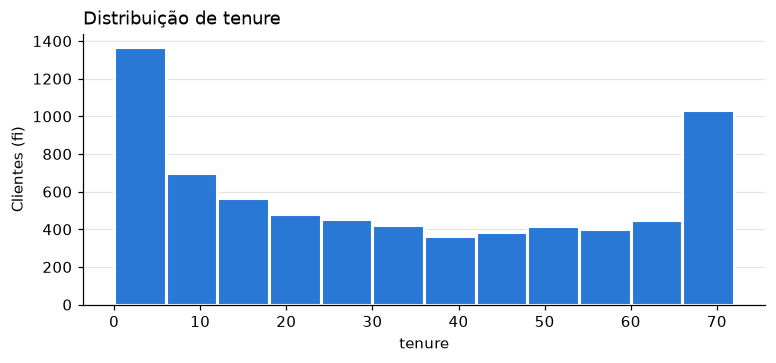

,Ponto Médio (xi),Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
Classes (MonthlyCharges),,,,,,
18.25 |--- 25.43,21.84,1511,0.2145,21.45%,1511,21.45%
25.43 |--- 32.61,29.02,179,0.0254,2.54%,1690,24.00%
32.61 |--- 39.79,36.20,143,0.0203,2.03%,1833,26.03%
39.79 |--- 46.96,43.38,311,0.0442,4.42%,2144,30.44%
46.96 |--- 54.14,50.55,372,0.0528,5.28%,2516,35.72%
54.14 |--- 61.32,57.73,478,0.0679,6.79%,2994,42.51%
61.32 |--- 68.50,64.91,280,0.0398,3.98%,3274,46.49%
68.50 |--- 75.68,72.09,750,0.1065,10.65%,4024,57.13%
75.68 |--- 82.86,79.27,614,0.0872,8.72%,4638,65.85%


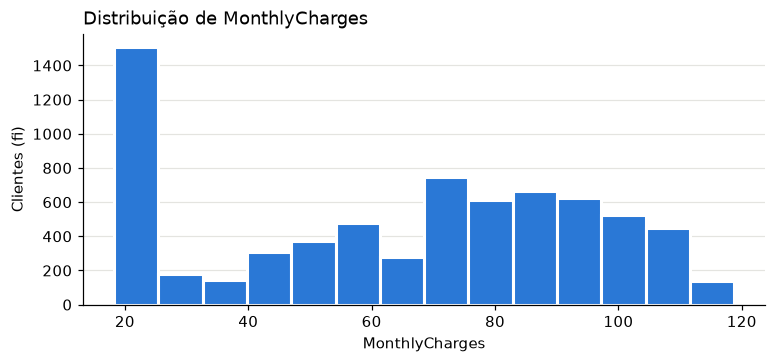

,Ponto Médio (xi),Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
Classes (TotalCharges),,,,,,
18.80 |--- 637.80,328.30,2269,0.3227,32.27%,2269,32.27%
"637.80 |--- 1,256.80",947.30,1026,0.1459,14.59%,3295,46.86%
"1,256.80 |--- 1,875.80","1,566.30",783,0.1113,11.13%,4078,57.99%
"1,875.80 |--- 2,494.80","2,185.30",449,0.0639,6.39%,4527,64.38%
"2,494.80 |--- 3,113.80","2,804.30",379,0.0539,5.39%,4906,69.77%
"3,113.80 |--- 3,732.80","3,423.30",336,0.0478,4.78%,5242,74.54%
"3,732.80 |--- 4,351.80","4,042.30",328,0.0466,4.66%,5570,79.21%
"4,351.80 |--- 4,970.80","4,661.30",312,0.0444,4.44%,5882,83.65%
"4,970.80 |--- 5,589.80","5,280.30",260,0.0370,3.70%,6142,87.34%


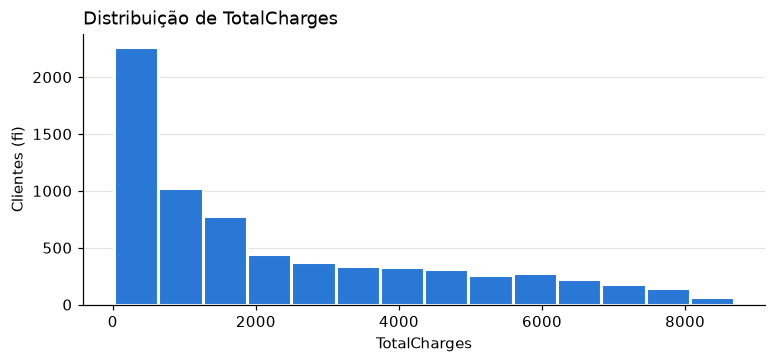

In [3]:
for coluna in continuas:
    largura = LARGURA.get(coluna)
    display(formatar_tabela(criar_tabela_frequencia(df, coluna, largura)))

    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.hist(df[coluna].dropna(), bins=calcular_classes(df[coluna], largura), color=AZUL,
            edgecolor='white', linewidth=2)
    ax.set_title(f'Distribuição de {coluna}', loc='left')
    ax.set_xlabel(coluna)
    ax.set_ylabel('Clientes (fi)')
    ax.grid(axis='x', visible=False)
    plt.show()

## 2. Distribuição de frequência — variáveis categóricas

In [4]:
display(formatar_tabela(resumo_categoricas(df, categoricas)))

## 3. Medidas de posição e dispersão

A moda das variáveis contínuas é estimada pela fórmula de Czuber sobre a classe modal da tabela de frequência, já que quase não há valores repetidos exatos.

In [5]:
resumo = pd.DataFrame({c: medidas_resumo(df[c], LARGURA.get(c)) for c in continuas})
display(resumo.style.format('{:,.2f}'))

for coluna in continuas:
    classe, _ = moda_czuber(df[coluna], LARGURA.get(coluna))
    print(f'Classe modal de {coluna}: {classe.left:,.2f} |--- {classe.right:,.2f}')

,tenure,MonthlyCharges,TotalCharges
Média,32.37,64.76,"2,283.30"
Mediana,29.00,70.35,"1,397.47"
Moda (Czuber),4.02,22.07,418.72
Desvio Padrão,24.56,30.09,"2,266.77"
Coef. Variação (%),75.87,46.46,99.28
Mínimo,0.00,18.25,18.80
Q1,9.00,35.50,401.45
Q3,55.00,89.85,"3,794.74"
Máximo,72.00,118.75,"8,684.80"
Amplitude Interquartil,46.00,54.35,"3,393.29"


Classe modal de tenure: 0.00 |--- 6.00
Classe modal de MonthlyCharges: 18.25 |--- 25.43
Classe modal de TotalCharges: 18.80 |--- 637.80


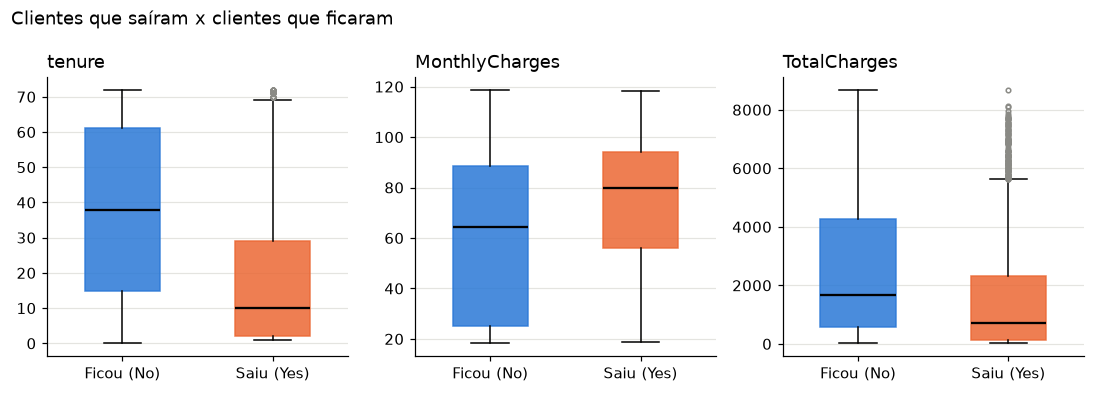

In [6]:
fig, axes = plt.subplots(1, len(continuas), figsize=(10, 3.6))
for ax, coluna in zip(axes, continuas):
    grupos = [df.loc[df['Churn'] == g, coluna].dropna() for g in ('No', 'Yes')]
    caixas = ax.boxplot(grupos, patch_artist=True, widths=0.5,
                        medianprops={'color': 'black', 'linewidth': 1.5},
                        flierprops={'markersize': 3, 'markeredgecolor': CINZA})
    for caixa, cor in zip(caixas['boxes'], (AZUL, LARANJA)):
        caixa.set(facecolor=cor, edgecolor=cor, alpha=0.85)
    ax.set_xticks([1, 2], ['Ficou (No)', 'Saiu (Yes)'])
    ax.set_title(coluna, loc='left')
    ax.grid(axis='x', visible=False)
fig.suptitle('Clientes que saíram x clientes que ficaram', x=0.01, ha='left')
fig.tight_layout()
plt.show()

## 4. Taxa de churn por variável

A linha tracejada marca a taxa geral da base. Barras acima dela indicam grupos de maior risco.

Taxa geral de churn: 26.5%


,Clientes,Churn (%)
Contract,,
Month-to-month,3875,42.7%
One year,1473,11.3%
Two year,1695,2.8%


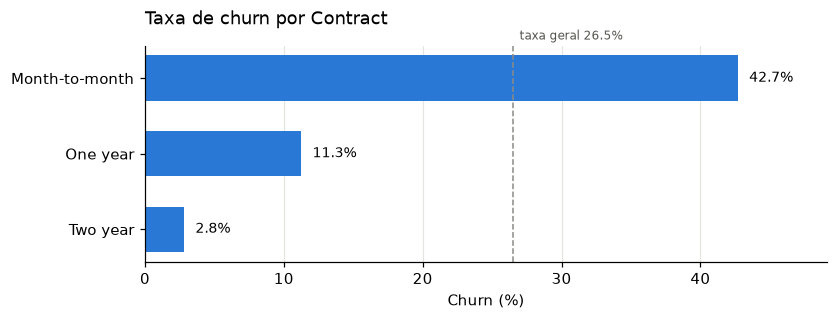

,Clientes,Churn (%)
InternetService,,
Fiber optic,3096,41.9%
DSL,2421,19.0%
No,1526,7.4%


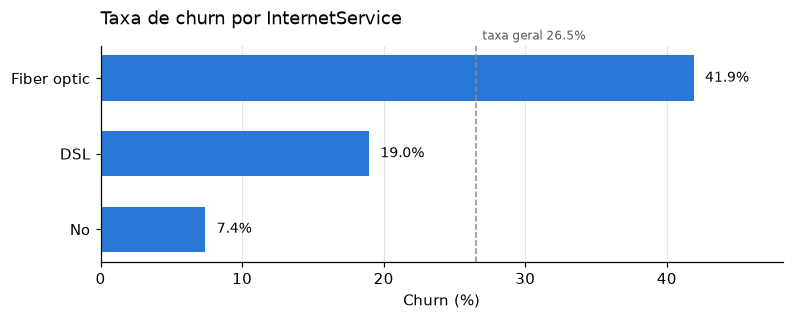

,Clientes,Churn (%)
PaymentMethod,,
Electronic check,2365,45.3%
Mailed check,1612,19.1%
Bank transfer (automatic),1544,16.7%
Credit card (automatic),1522,15.2%


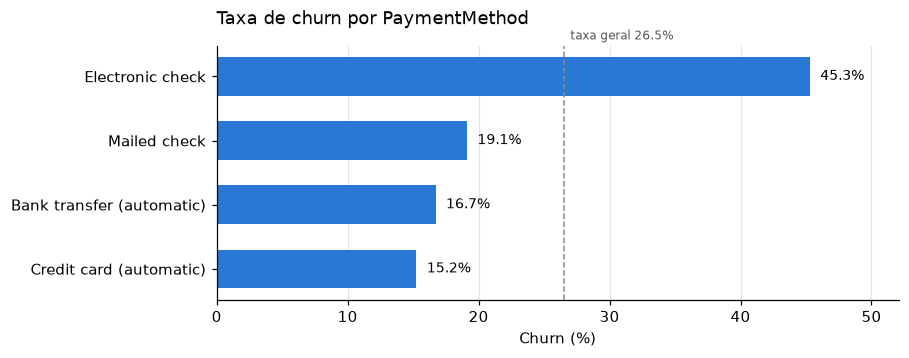

,Clientes,Churn (%)
Faixa de tenure (meses),,
0 |--- 6,1371,54.3%
6 |--- 12,698,36.5%
12 |--- 18,568,33.6%
18 |--- 24,479,24.6%
24 |--- 30,453,22.3%
30 |--- 36,423,21.7%
36 |--- 42,364,21.7%
42 |--- 48,384,17.4%
48 |--- 54,416,15.4%


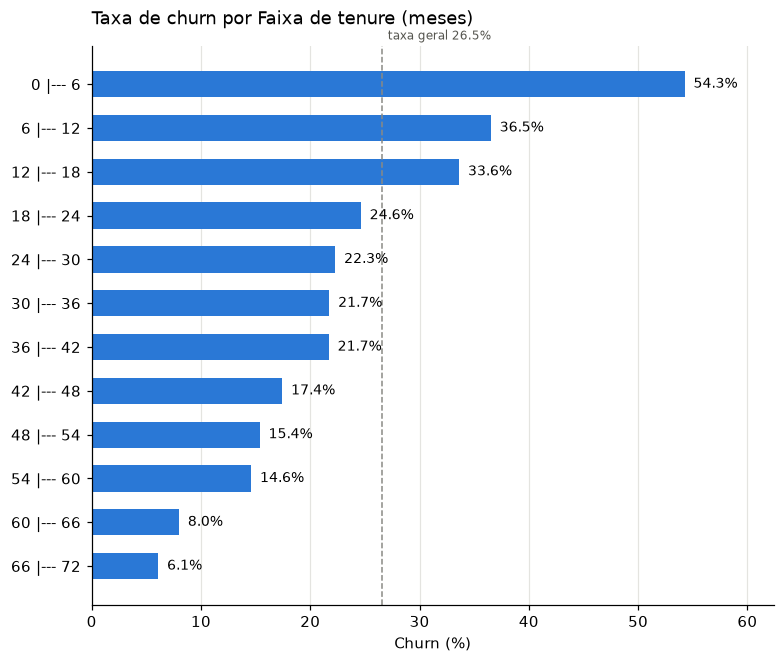

In [7]:
print(f'Taxa geral de churn: {taxa_geral:.1f}%')
df_faixas = df.assign(**{'Faixa de tenure (meses)': classificar(df['tenure'], LARGURA['tenure'])})

for coluna in ['Contract', 'InternetService', 'PaymentMethod', 'Faixa de tenure (meses)']:
    tabela = taxa_churn(df_faixas, coluna)
    if coluna.startswith('Faixa'):
        tabela = tabela.sort_index()  # faixas seguem a ordem natural
    display(tabela.style.format({'Churn (%)': '{:.1f}%'}))

    fig, ax = plt.subplots(figsize=(8, 0.45 * len(tabela) + 1.2))
    ax.barh(tabela.index.astype(str), tabela['Churn (%)'], color=AZUL, height=0.6)
    ax.invert_yaxis()
    ax.axvline(taxa_geral, color=CINZA, linestyle='--', linewidth=1)
    ax.annotate(f'taxa geral {taxa_geral:.1f}%', xy=(taxa_geral, 1), xycoords=('data', 'axes fraction'),
                xytext=(4, 2), textcoords='offset points', fontsize=8, color='#55554f', va='bottom')
    for i, v in enumerate(tabela['Churn (%)']):
        ax.text(v + 0.8, i, f'{v:.1f}%', va='center', fontsize=9)
    ax.set_xlim(0, tabela['Churn (%)'].max() * 1.15)
    ax.set_xlabel('Churn (%)')
    ax.set_title(f'Taxa de churn por {coluna}', loc='left', pad=14)
    ax.grid(axis='y', visible=False)
    plt.show()

## 5. Testes de associação com o churn

- **Categóricas:** qui-quadrado de independência. O tamanho do efeito é medido pelo **V de Cramér** (cerca de 0,1 é pequeno, 0,3 é médio e 0,5 é grande).
- **Contínuas:** Mann-Whitney comparando quem saiu e quem ficou, porque as distribuições não são normais. O efeito é medido pela **correlação rank-biserial**, que vai de -1 a 1 e é positiva quando quem saiu tem valores maiores.

Com 7 mil clientes, quase qualquer diferença dá p-valor < 0,05. Por isso as tabelas estão ordenadas pelo tamanho do efeito, que é o que mostra a força da associação.

In [8]:
categoricas_X = [c for c in categoricas if c != 'Churn']

qui2 = pd.DataFrame({c: teste_qui_quadrado(df, c) for c in categoricas_X}).T
qui2 = qui2.sort_values('V de Cramér', ascending=False)
display(qui2.style.format({'Qui-quadrado': '{:,.1f}', 'gl': '{:.0f}', 'p-valor': '{:.2e}',
                           'V de Cramér': '{:.3f}'}))

mw = pd.DataFrame({c: teste_mann_whitney(df, c) for c in continuas}).T
mw = mw.sort_values('Rank-biserial', key=abs, ascending=False)
display(mw.style.format({'Mediana (saiu)': '{:,.2f}', 'Mediana (ficou)': '{:,.2f}',
                         'U': '{:,.0f}', 'p-valor': '{:.2e}', 'Rank-biserial': '{:+.3f}'}))

,Qui-quadrado,gl,p-valor,V de Cramér
Contract,"1,184.6",2,5.86e-258,0.410
OnlineSecurity,850.0,2,2.66e-185,0.347
TechSupport,828.2,2,1.44e-180,0.343
InternetService,732.3,2,9.57e-160,0.322
PaymentMethod,648.1,3,3.68e-140,0.303
OnlineBackup,601.8,2,2.08e-131,0.292
DeviceProtection,558.4,2,5.51e-122,0.282
StreamingMovies,375.7,2,2.67e-82,0.231
StreamingTV,374.2,2,5.53e-82,0.231
PaperlessBilling,258.3,1,4.07e-58,0.191


,Mediana (saiu),Mediana (ficou),U,p-valor,Rank-biserial
tenure,10.00,38.00,"2,515,538",2.42e-208,-0.480
TotalCharges,703.55,"1,683.60","3,360,665",2.00e-84,-0.303
MonthlyCharges,79.65,64.43,"6,003,126",3.31e-54,+0.242


## 6. Modelos de previsão

**Colinearidade:** `TotalCharges` é praticamente `tenure × MonthlyCharges`. Com as três variáveis juntas, os coeficientes da regressão logística ficam instáveis e trocam de sinal (por exemplo, `TotalCharges` parecia aumentar o churn). Por isso `TotalCharges` fica de fora dos modelos.

In [9]:
estimado = df['tenure'] * df['MonthlyCharges']
print(f"Correlação entre TotalCharges e tenure × MonthlyCharges: {df['TotalCharges'].corr(estimado):.3f}")

Correlação entre TotalCharges e tenure × MonthlyCharges: 1.000


Três modelos são comparados com **validação cruzada estratificada de 5 partes** no conjunto de treino. O conjunto de teste (25%) só é usado no final. Todos usam `class_weight='balanced'`, porque só 26,5% dos clientes saem.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numericas_X = ['tenure', 'MonthlyCharges']
X = df[numericas_X + categoricas_X]
y = (df['Churn'] == 'Yes').astype(int)

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

def pipeline(classificador):
    return make_pipeline(
        ColumnTransformer([
            ('num', StandardScaler(), numericas_X),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas_X),
        ]),
        classificador,
    )

modelos = {
    'Regressão Logística': pipeline(LogisticRegression(max_iter=1000, class_weight='balanced')),
    'Random Forest': pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                     class_weight='balanced', random_state=42, n_jobs=-1)),
    'Gradient Boosting': pipeline(HistGradientBoostingClassifier(class_weight='balanced', random_state=42)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados = {}
for nome, modelo in modelos.items():
    r = cross_validate(modelo, X_treino, y_treino, cv=cv, scoring=['roc_auc', 'recall', 'precision', 'f1'])
    resultados[nome] = {f'{m} (média)': r[f'test_{m}'].mean() for m in ['roc_auc', 'recall', 'precision', 'f1']}
    resultados[nome]['roc_auc (desvio)'] = r['test_roc_auc'].std()

comparacao = pd.DataFrame(resultados).T.sort_values('roc_auc (média)', ascending=False)
display(comparacao.style.format('{:.3f}'))
melhor = comparacao.index[0]
print(f'Melhor modelo na validação cruzada: {melhor}')

,roc_auc (média),recall (média),precision (média),f1 (média),roc_auc (desvio)
Regressão Logística,0.842,0.790,0.516,0.624,0.015
Random Forest,0.841,0.757,0.533,0.625,0.015
Gradient Boosting,0.835,0.727,0.538,0.618,0.012


Melhor modelo na validação cruzada: Regressão Logística


### Limiar de decisão pelo custo

O limiar padrão de 0,5 não leva em conta que errar para cada lado custa diferente. Os custos abaixo são **hipotéticos**; ajuste para a realidade do negócio:

- `CUSTO_ACAO`: custo de uma ação de retenção (contato e desconto), aplicada a todo cliente marcado como risco;
- `CUSTO_PERDA`: custo de perder um cliente que cancelaria e não foi abordado.

O limiar é escolhido com as probabilidades da validação cruzada no treino e só depois aplicado no teste.

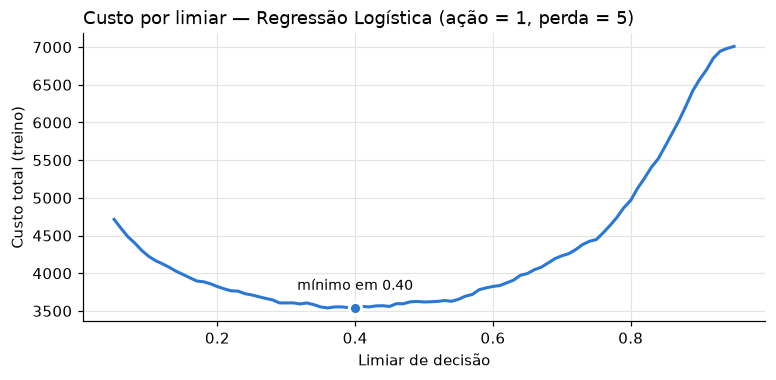

In [11]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import cross_val_predict

CUSTO_ACAO = 1
CUSTO_PERDA = 5

def custo_total(y_real, prob, limiar):
    tn, fp, fn, tp = confusion_matrix(y_real, prob >= limiar).ravel()
    return (tp + fp) * CUSTO_ACAO + fn * CUSTO_PERDA

modelo_final = modelos[melhor]
prob_cv = cross_val_predict(modelo_final, X_treino, y_treino, cv=cv, method='predict_proba')[:, 1]
limiares = np.round(np.arange(0.05, 0.96, 0.01), 2)
custos = np.array([custo_total(y_treino, prob_cv, l) for l in limiares])
limiar = limiares[custos.argmin()]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(limiares, custos, color=AZUL, linewidth=2)
ax.plot(limiar, custos.min(), 'o', color=AZUL, markersize=8, markeredgecolor='white', markeredgewidth=2)
ax.annotate(f'mínimo em {limiar:.2f}', (limiar, custos.min()), xytext=(0, 12),
            textcoords='offset points', fontsize=9, ha='center')
ax.set_xlabel('Limiar de decisão')
ax.set_ylabel('Custo total (treino)')
ax.set_title(f'Custo por limiar — {melhor} (ação = {CUSTO_ACAO}, perda = {CUSTO_PERDA})', loc='left')
plt.show()

In [12]:
modelo_final.fit(X_treino, y_treino)
prob_teste = modelo_final.predict_proba(X_teste)[:, 1]

print(f'Modelo: {melhor} | ROC-AUC no teste: {roc_auc_score(y_teste, prob_teste):.3f}')
print(f'Acurácia de sempre prever "No": {1 - y_teste.mean():.3f}\n')
for nome_limiar, l in [('padrão 0,50', 0.5), (f'por custo {limiar:.2f}', limiar)]:
    print(f'--- Limiar {nome_limiar} | custo no teste: {custo_total(y_teste, prob_teste, l):,}')
    print(classification_report(y_teste, prob_teste >= l, target_names=['Ficou (No)', 'Saiu (Yes)'], digits=3))

Modelo: Regressão Logística | ROC-AUC no teste: 0.844
Acurácia de sempre prever "No": 0.735

--- Limiar padrão 0,50 | custo no teste: 1,194
              precision    recall  f1-score   support

  Ficou (No)      0.907     0.741     0.816      1294
  Saiu (Yes)      0.524     0.790     0.630       467

    accuracy                          0.754      1761
   macro avg      0.716     0.766     0.723      1761
weighted avg      0.806     0.754     0.767      1761

--- Limiar por custo 0.40 | custo no teste: 1,171
              precision    recall  f1-score   support

  Ficou (No)      0.930     0.654     0.768      1294
  Saiu (Yes)      0.474     0.863     0.612       467

    accuracy                          0.709      1761
   macro avg      0.702     0.758     0.690      1761
weighted avg      0.809     0.709     0.726      1761



### O que mais pesa na regressão logística

Coeficientes sobre variáveis padronizadas, sem `TotalCharges`. Valores positivos aumentam a chance de churn.

`MonthlyCharges` aparece com sinal negativo, apesar de quem sai pagar mais. Isso acontece porque a mensalidade é quase toda explicada pelos serviços contratados (fibra, streaming etc.), que já estão no modelo. O coeficiente mede o efeito de pagar mais **pelos mesmos serviços**, e não o efeito de ter uma mensalidade alta em geral.

In [13]:
logistica = modelos['Regressão Logística'].fit(X_treino, y_treino)
nomes = logistica[0].get_feature_names_out()
coeficientes = pd.Series(logistica[-1].coef_[0], index=nomes).sort_values()
display(pd.concat([coeficientes.head(5), coeficientes.tail(5)])
          .rename('Coeficiente').to_frame()
          .style.format('{:+.3f}'))

,Coeficiente
num__tenure,-0.736
cat__Contract_Two year,-0.726
cat__InternetService_DSL,-0.609
num__MonthlyCharges,-0.540
cat__PaperlessBilling_No,-0.266
cat__OnlineSecurity_No,+0.207
cat__StreamingTV_Yes,+0.264
cat__StreamingMovies_Yes,+0.304
cat__Contract_Month-to-month,+0.647
cat__InternetService_Fiber optic,+0.708
